# ML Assignment 2 – Bank Marketing Classification

**Goal:** predict whether a client subscribes to a term deposit (`y`), comparing five classifiers with six metrics.

**Dataset:** UCI Bank Marketing, `bank-additional-full.csv`

## Contents
1. Setup and load data
2. Data understanding
3. Preprocessing, split and Logistic Regression baseline
4. Other models, comparison and export

## 1. Setup and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


In [2]:
# The file is semicolon-separated
data = pd.read_csv('data/bank-additional-full.csv', sep=';')
print('Shape:', data.shape)
data.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data understanding

### 2.1 Structure, data types and summary statistics

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### 2.2 Missing values and duplicates

In [5]:
print('Null values per column:')
print(data.isnull().sum()[data.isnull().sum() > 0] if data.isnull().sum().sum() else 'None - no null values')
print('\nDuplicate rows:', data.duplicated().sum())

Null values per column:
None - no null values

Duplicate rows: 12


In [6]:
# Categorical columns use the string 'unknown' as a missing-value marker
cat_cols = data.drop(columns='y').select_dtypes(exclude='number').columns.tolist()
unknown_counts = (data[cat_cols] == 'unknown').sum()
unknown_counts[unknown_counts > 0].sort_values(ascending=False).to_frame('unknown_count').assign(
    pct=lambda d: (d.unknown_count / len(data) * 100).round(2))

,unknown_count,pct
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


**Findings**
- There are no real `NaN` values, but several categorical columns hold `'unknown'` (largest share: `default`). These will be treated as their own category rather than dropped.
- There are a small number of exact duplicate rows; they will be removed before splitting (next stage) so the same record cannot appear in both train and test.

### 2.3 Target variable (`y`)

     count  percent
y                  
no   36548    88.73
yes   4640    11.27


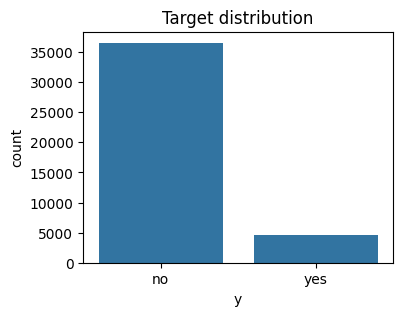

In [7]:
counts = data['y'].value_counts()
pct = data['y'].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({'count': counts, 'percent': pct}))

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(data=data, x='y', ax=ax)
ax.set_title('Target distribution')
plt.show()

**Finding:** the target is imbalanced (about 11% `yes`). Accuracy alone would be misleading - a model that always predicts `no` scores about 89%. Precision, recall, F1, AUC and especially MCC will be needed to judge the models, and the train/test split must be **stratified**.

### 2.4 Numerical and categorical predictors

In [8]:
X_all = data.drop(columns='y')
num_cols = X_all.select_dtypes(include='number').columns.tolist()
cat_cols = X_all.select_dtypes(exclude='number').columns.tolist()
print(f'Numerical predictors ({len(num_cols)}):', num_cols)
print(f'Categorical predictors ({len(cat_cols)}):', cat_cols)
print('Total predictors:', X_all.shape[1])

Numerical predictors (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical predictors (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Total predictors: 20


In [9]:
data[cat_cols].nunique().sort_values(ascending=False).to_frame('unique_values')

,unique_values
job,12
month,10
education,8
day_of_week,5
marital,4
default,3
loan,3
housing,3
poutcome,3
contact,2


### 2.5 Distributions and relationships

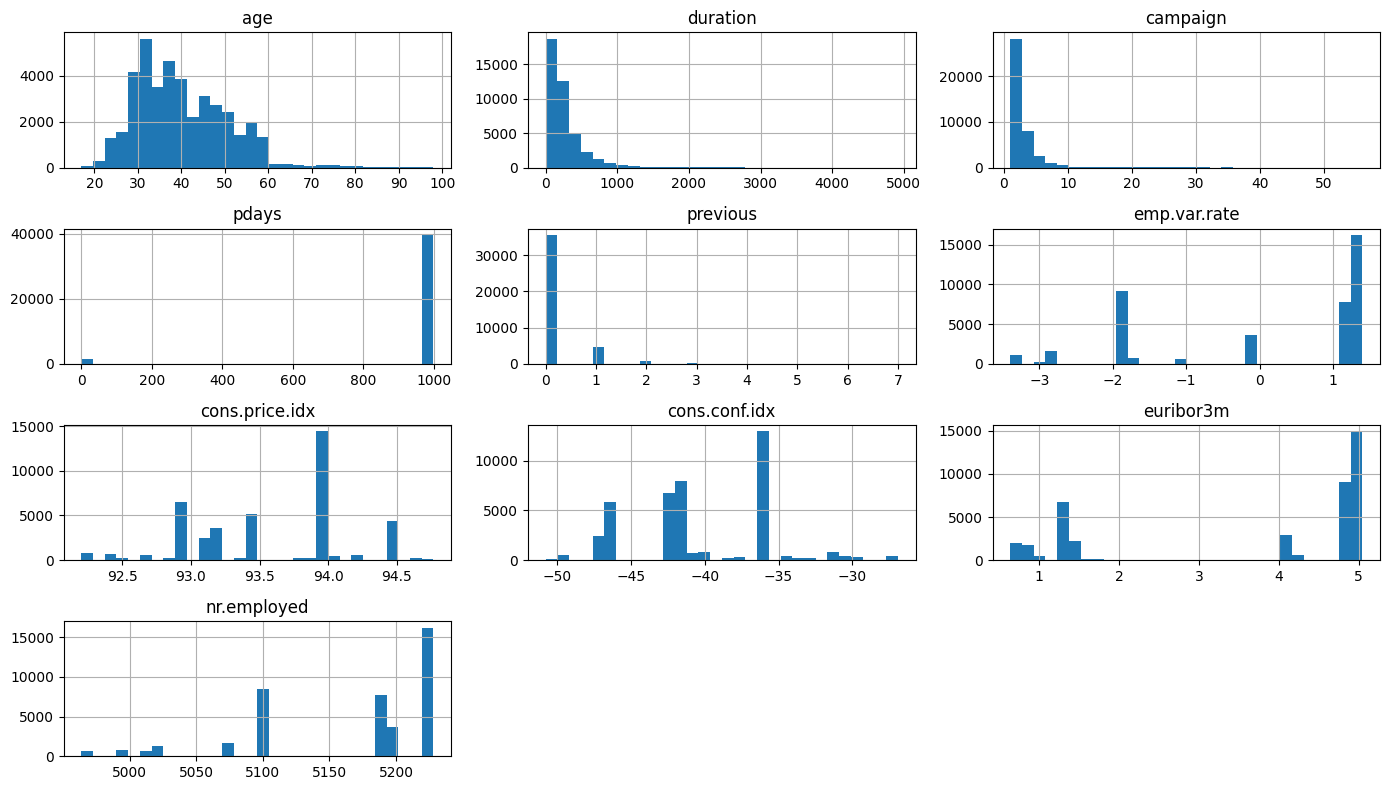

In [10]:
data[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

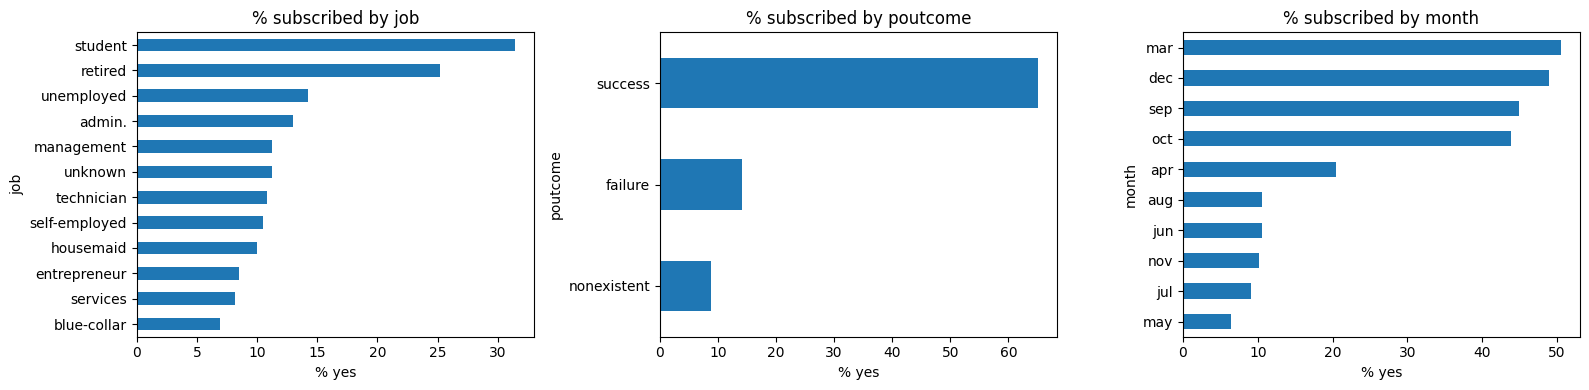

In [11]:
# Subscription rate by category for a few key categorical features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['job', 'poutcome', 'month']):
    rate = data.groupby(col)['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()
    rate.plot(kind='barh', ax=ax)
    ax.set_title(f'% subscribed by {col}')
    ax.set_xlabel('% yes')
plt.tight_layout()
plt.show()

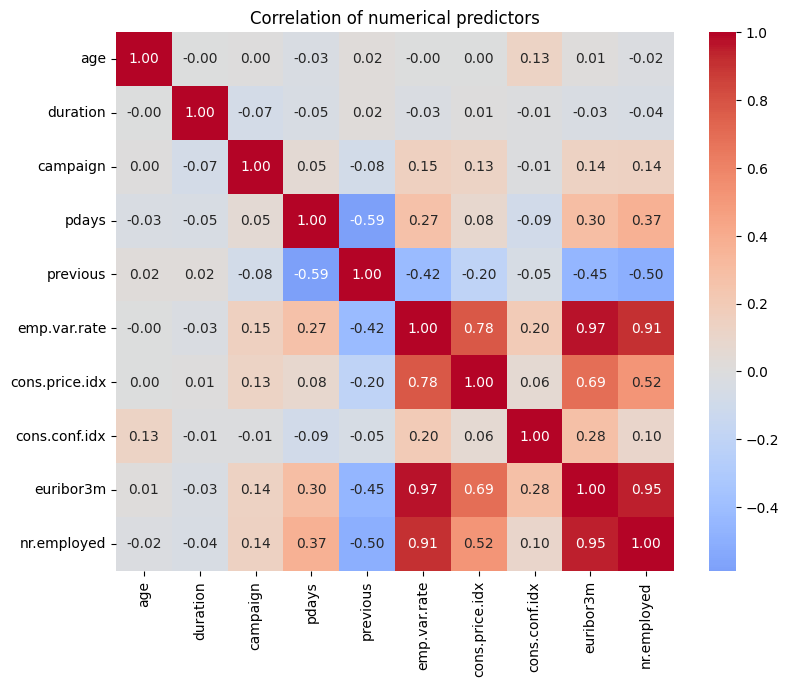

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numerical predictors')
plt.show()

**Findings**
- `pdays` uses the code `999` for 'client not previously contacted', so it is not a true numeric distance and is highly skewed.
- `campaign`, `previous` and `duration` are right-skewed; scaling will matter for Logistic Regression, KNN and SVM.
- Macro-economic features (`emp.var.rate`, `euribor3m`, `nr.employed`) are strongly correlated with each other (multicollinearity), which is acceptable for tree models but worth noting for Logistic Regression.
- `duration` (call length) is only known after the call ends, so it would not be available for a real pre-call prediction. It is kept here because it is part of the assignment dataset, and this limitation will be stated in the README.

## 3. Preprocessing and Logistic Regression baseline

### 3.0 Decisions carried forward from data understanding (Section 2)
- **Size and types:** 41,188 rows, 20 predictors (10 numerical, 10 categorical), binary target `y`.
- **Missing values:** no real nulls; `'unknown'` is kept as its own category.
- **Duplicates:** 12 exact duplicate rows are removed *before* splitting so a record cannot appear in both train and test.
- **Imbalance (~11% `yes`):** use a **stratified** split and judge models with precision, recall, F1, AUC and MCC, not accuracy alone.
- **Scaling:** skewed numeric features and distance/margin-based models (KNN, SVM, Logistic Regression) need scaling, applied inside a pipeline.
- **`pdays = 999`** is kept as-is (it means 'not previously contacted'); `duration` is kept because it is part of the assignment dataset, with its limitation noted in the README.

### 3.1 Clean data and define features and target

In [13]:
rows_before = len(data)
data_clean = data.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {rows_before}, after removing duplicates: {len(data_clean)} (removed {rows_before - len(data_clean)})')

X = data_clean.drop(columns='y')
y = data_clean['y'].map({'no': 0, 'yes': 1})   # positive class = 1 = subscribed
print('Features:', X.shape, '| Target counts:', y.value_counts().to_dict())

Rows before: 41188, after removing duplicates: 41176 (removed 12)
Features: (41176, 20) | Target counts: {0: 36537, 1: 4639}


### 3.2 Train/test split (stratified, before any fitting)
The split comes first so that no preprocessing step ever sees the test data (no data leakage).

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Positive rate  train: %.4f  test: %.4f' % (y_train.mean(), y_test.mean()))

Train: (32940, 20) | Test: (8236, 20)
Positive rate  train: 0.1127  test: 0.1127


### 3.3 Preprocessing with `ColumnTransformer`
- Numerical columns: `StandardScaler`.
- Categorical columns: `OneHotEncoder(handle_unknown='ignore')` so unseen categories in uploaded data do not crash the app.

The transformer is fitted only on the training data, inside each model's `Pipeline`.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
print(len(num_cols), 'numerical +', len(cat_cols), 'categorical columns')

10 numerical + 10 categorical columns


### 3.4 Reusable evaluation function
One function computes all six required metrics so every model is measured identically. AUC uses probability / decision scores, not hard predictions.

In [16]:
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

results = []   # one row per model, filled in as we go

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred),
    }
    return row, y_pred

def show_confusion(y_true, y_pred, title):
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=['no', 'yes']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)
    plt.show()

### 3.5 Model 1: Logistic Regression (baseline)

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42)),
])
logistic_pipeline.fit(X_train, y_train)

row, pred_lr = evaluate_model('Logistic Regression', logistic_pipeline, X_test, y_test)
results.append(row)
pd.DataFrame([row]).set_index('Model').round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9095,0.939,0.6522,0.4224,0.5128,0.4788


              precision    recall  f1-score   support

          no       0.93      0.97      0.95      7308
         yes       0.65      0.42      0.51       928

    accuracy                           0.91      8236
   macro avg       0.79      0.70      0.73      8236
weighted avg       0.90      0.91      0.90      8236



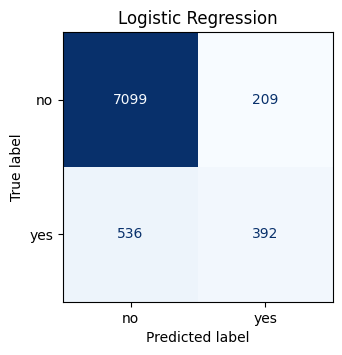

In [18]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred_lr, target_names=['no', 'yes']))
show_confusion(y_test, pred_lr, 'Logistic Regression')

### Observation – Logistic Regression
- **Accuracy looks strong but is misleading:** 90.95% accuracy is only about 2 points above the 88.7% obtained by always predicting `no`, because the data is imbalanced.
- **The minority class is poorly detected:** recall for `yes` is 0.42, so the model finds only 392 of the 928 actual subscribers and misses 536 (false negatives). Precision is 0.65 (209 false positives), which gives an F1 of 0.51.
- **MCC (0.48) and AUC (0.94) tell different stories:** the high AUC shows the model *ranks* subscribers above non-subscribers well, but the default 0.5 decision threshold is too conservative for a rare positive class. Tuning the threshold or using class weights could raise recall (not done here, so that all five models are compared under identical default settings).
- **Baseline for comparison:** the next models are judged against recall 0.42, F1 0.51 and MCC 0.48.

### 3.6 Model 2: Decision Tree

In [19]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42)),
])
decision_tree_pipeline.fit(X_train, y_train)

row, pred_dt = evaluate_model('Decision Tree', decision_tree_pipeline, X_test, y_test)
results.append(row)
pd.DataFrame([row]).set_index('Model').round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Decision Tree,0.8902,0.7246,0.513,0.5108,0.5119,0.45


              precision    recall  f1-score   support

          no       0.94      0.94      0.94      7308
         yes       0.51      0.51      0.51       928

    accuracy                           0.89      8236
   macro avg       0.73      0.72      0.73      8236
weighted avg       0.89      0.89      0.89      8236



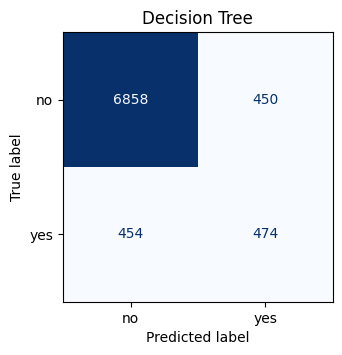

Train accuracy: 1.0000 | Test accuracy: 0.8902
Tree depth: 28 | Leaves: 2353


In [20]:
print(classification_report(y_test, pred_dt, target_names=['no', 'yes']))
show_confusion(y_test, pred_dt, 'Decision Tree')

# Overfitting check: an unrestricted tree can memorise the training set
train_acc = decision_tree_pipeline.score(X_train, y_train)
test_acc = decision_tree_pipeline.score(X_test, y_test)
print(f'Train accuracy: {train_acc:.4f} | Test accuracy: {test_acc:.4f}')
print('Tree depth:', decision_tree_pipeline.named_steps['classifier'].get_depth(),
      '| Leaves:', decision_tree_pipeline.named_steps['classifier'].get_n_leaves())

### Observation – Decision Tree
- **Severe overfitting:** the unrestricted tree reaches 100% training accuracy (depth 28, 2,353 leaves) but only 89.0% on test data, so it memorised the training set rather than learning a general pattern.
- **Weak ranking (AUC 0.72):** this is the lowest AUC so far, far below Logistic Regression (0.94). A fully grown tree outputs almost only 0 or 1 probabilities, so it cannot rank clients by likelihood of subscribing.
- **Best recall, lower precision:** recall for `yes` is 0.51, the highest so far, but precision drops to 0.51, so F1 (0.51) and MCC (0.45) end up no better than the Logistic Regression baseline (0.51 / 0.48).
- **Takeaway:** a depth limit (`max_depth`, `min_samples_leaf`) or pruning would likely generalise better, but the default settings are kept so every model is compared fairly.

### 3.7 Model 3: K-Nearest Neighbors

In [21]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5)),
])
knn_pipeline.fit(X_train, y_train)

row, pred_knn = evaluate_model('K-Nearest Neighbors', knn_pipeline, X_test, y_test)
results.append(row)
pd.DataFrame([row]).set_index('Model').round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
K-Nearest Neighbors,0.9014,0.8741,0.5858,0.4267,0.4938,0.4474


              precision    recall  f1-score   support

          no       0.93      0.96      0.95      7308
         yes       0.59      0.43      0.49       928

    accuracy                           0.90      8236
   macro avg       0.76      0.69      0.72      8236
weighted avg       0.89      0.90      0.89      8236



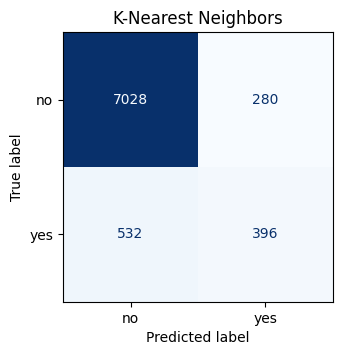

In [22]:
print(classification_report(y_test, pred_knn, target_names=['no', 'yes']))
show_confusion(y_test, pred_knn, 'K-Nearest Neighbors')

### Observation – K-Nearest Neighbors
- **Accuracy is similar to the baseline (0.901), but minority-class performance is weak:** recall for `yes` is 0.43 and precision 0.59, giving F1 0.49 and MCC 0.45, the lowest F1 of the three models so far.
- **AUC 0.87:** better than the Decision Tree (0.72) because averaging the labels of 5 neighbours gives graded scores, but below Logistic Regression (0.94).
- **Why it struggles:** after one-hot encoding there are many sparse binary columns, so distances become less informative in high dimensions, and with k=5 the 11% `yes` class is easily outvoted by its `no` neighbours.
- **Cost:** KNN stores the whole training set and is slow at prediction time, which is a drawback for deployment.

### 3.8 Model 4: Gaussian Naive Bayes
`GaussianNB` needs a dense array, so this model uses the same preprocessing steps with `sparse_output=False` for the one-hot encoder.

In [23]:
from sklearn.naive_bayes import GaussianNB

preprocessor_dense = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])

naive_bayes_pipeline = Pipeline([
    ('preprocessor', preprocessor_dense),
    ('classifier', GaussianNB()),
])
naive_bayes_pipeline.fit(X_train, y_train)

row, pred_nb = evaluate_model('Naive Bayes', naive_bayes_pipeline, X_test, y_test)
results.append(row)
pd.DataFrame([row]).set_index('Model').round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Naive Bayes,0.8227,0.8404,0.3506,0.6724,0.4609,0.395


              precision    recall  f1-score   support

          no       0.95      0.84      0.89      7308
         yes       0.35      0.67      0.46       928

    accuracy                           0.82      8236
   macro avg       0.65      0.76      0.68      8236
weighted avg       0.89      0.82      0.85      8236



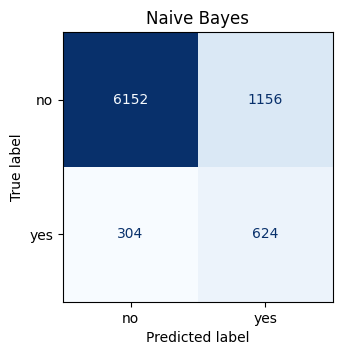

In [24]:
print(classification_report(y_test, pred_nb, target_names=['no', 'yes']))
show_confusion(y_test, pred_nb, 'Naive Bayes')

### Observation – Naive Bayes
- **Opposite trade-off to the other models:** recall for `yes` is 0.67, the highest of all models so far, but precision is only 0.35, so it flags many non-subscribers (accuracy drops to 0.82, the lowest).
- **Why:** Naive Bayes assumes features are independent given the class and (for `GaussianNB`) that each is normally distributed. Here the one-hot columns are binary and the macro-economic features (`emp.var.rate`, `euribor3m`, `nr.employed`) are strongly correlated, so the assumptions are violated and the model over-predicts the `yes` class.
- **Overall:** F1 (0.46) and MCC (0.40) are the lowest of the models so far, although AUC (0.84) is reasonable. It would only be preferred if missing a subscriber costs much more than contacting a non-subscriber.

### 3.9 Model 5: Support Vector Machine (RBF kernel)
SVM is the slowest model on 33k training rows. `probability=True` is not used (it triggers an extra internal cross-validation that multiplies the training time, and is deprecated in recent scikit-learn); AUC is computed from `decision_function` scores instead, which `evaluate_model()` already supports.

In [25]:
import time
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', random_state=42)),
])

start = time.time()
svm_pipeline.fit(X_train, y_train)
print(f'SVM training time: {time.time() - start:.1f} s')

row, pred_svm = evaluate_model('Support Vector Machine', svm_pipeline, X_test, y_test)
results.append(row)
pd.DataFrame([row]).set_index('Model').round(4)

SVM training time: 28.2 s


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Support Vector Machine,0.9119,0.9163,0.6683,0.4321,0.5249,0.4926


              precision    recall  f1-score   support

          no       0.93      0.97      0.95      7308
         yes       0.67      0.43      0.52       928

    accuracy                           0.91      8236
   macro avg       0.80      0.70      0.74      8236
weighted avg       0.90      0.91      0.90      8236



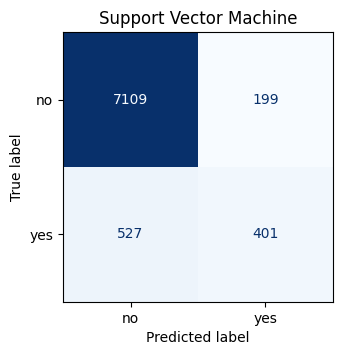

In [26]:
print(classification_report(y_test, pred_svm, target_names=['no', 'yes']))
show_confusion(y_test, pred_svm, 'Support Vector Machine')

### Observation – Support Vector Machine
- **Best on the thresholded metrics:** the RBF SVM has the highest accuracy (0.912), precision (0.668), F1 (0.525) and MCC (0.493) of the five models, though only slightly ahead of Logistic Regression.
- **AUC (0.916) is below Logistic Regression (0.939):** the SVM separates the classes well at its decision boundary but ranks clients slightly less well across thresholds.
- **Minority-class recall is still low (0.43):** like Logistic Regression and KNN, it misses more than half of the actual subscribers at the default setting, so class weighting or threshold tuning would be needed in practice.
- **Cost:** training took about 14 seconds here; SVM training time grows quickly with the number of rows.

### 3.10 Results of all five models

In [27]:
pd.DataFrame(results).set_index('Model').round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9095,0.9390,0.6522,0.4224,0.5128,0.4788
Decision Tree,0.8902,0.7246,0.5130,0.5108,0.5119,0.4500
K-Nearest Neighbors,0.9014,0.8741,0.5858,0.4267,0.4938,0.4474
Naive Bayes,0.8227,0.8404,0.3506,0.6724,0.4609,0.3950
Support Vector Machine,0.9119,0.9163,0.6683,0.4321,0.5249,0.4926
